# 35 — DLM em painel: AIC × BIC, TWFE e perfis defasados

Modelo da monografia: $$Y_{i,t}=\alpha_i+\lambda_t+\sum_{k=0}^{K}\beta_k X_{i,t-k}+\varepsilon_{i,t}.$$

Resposta: $Y_{it}=\Delta\log(I_{it})$; exposição de cada tipologia: $X_{it}=\Delta\log(1+D_{it})$. Uma tipologia por DLM. Efeitos fixos da UF e do mês-ano. Estimador MQO após retirada dos efeitos fixos.

Os candidatos $K=1,\ldots,24$ utilizam **uma amostra comum** por período. Seleção independente de K por AIC e BIC; aplicação das cinco hipóteses e das correções de multiplicidade.

## 1. Base e transformações

In [1]:
from pathlib import Path
import os, sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'src'))
if 'TCC_BASE_CSV' not in os.environ:
    os.environ['TCC_BASE_CSV']=str(ROOT/'data/processed/df_tcc_2013_2024.csv')
from analise_estadual import load, TIPOS
D=ROOT/'outputs/tables/revisao_estadual_20261019'
A=ROOT/'outputs/tables/auditoria_metodologica_20261020'
S=ROOT/'outputs/tables/sarimax_criterios_independentes_20261020'
df=load()
print(f'Painel: {len(df)} observações, {df.uf.nunique()} UFs, {df.mes_ano.nunique()} meses, {len(TIPOS)} tipologias')

Painel: 3888 observações, 27 UFs, 144 meses, 16 tipologias


## 2. Horizonte K por AIC e por BIC

In [2]:
# Para refazer os 696 candidatos K disponíveis (29*24), marque True.
REESTIMAR=False
if REESTIMAR:
    from analise_estadual import dlm
    _=dlm(df)
sel=pd.read_csv(D/'dlm_selecao.csv')
s=sel.pivot_table(index=['periodo','tipologia'],columns='criterio',values='K').reset_index()
s['K_diferente']=s.AIC.ne(s.BIC)
print('Aplicações estimáveis',len(s),'K diferentes',int(s.K_diferente.sum()))
print('Comparações diferentes:')
print(s[s.K_diferente].to_string(index=False))

Aplicações estimáveis 29 K diferentes 8
Comparações diferentes:
periodo                            tipologia  AIC  BIC  K_diferente
    Pré                 tipo_chuvas_intensas 15.0  1.0         True
    Pré            tipo_vendavais_e_ciclones 14.0  1.0         True
  Total                 tipo_chuvas_intensas 16.0  1.0         True
  Total              tipo_incendio_florestal  6.0  1.0         True
  Total              tipo_movimento_de_massa  5.0  1.0         True
  Total   tipo_onda_de_calor_e_baixa_umidade 14.0  1.0         True
  Total tipo_rompimento_colapso_de_barragens  4.0  1.0         True
  Total            tipo_vendavais_e_ciclones  9.0  1.0         True


## 3. Inferência com cinco hipóteses

* Contemporâneo $\beta_0=0$; soma total $\sum_{k=0}^K\beta_k=0$; soma defasada $\sum_{k=1}^K\beta_k=0$; conjunto completo; conjunto defasado.
* Covariâncias: cluster UF, DK regra, DK6, DK12. A banda DK é diferente do horizonte K da exposição.
* Proteção conservadora $\min(24p,1)$ + BH por período × critério × covariância × hipótese. Não constitui inferência seletiva exata.

In [3]:
h=pd.read_csv(D/'dlm_hipoteses.csv')
main=h[(h.criterio=='BIC')&(h.covariancia=='dk_regra')]
print('BIC + DK regra: rejeições protegidas',int(main.rejeicao_bh_grade.sum()))
print('Rejeições AIC + DK regra:')
print(h[(h.criterio=='AIC')&(h.covariancia=='dk_regra')&(h.rejeicao_bh_grade)][['periodo','tipologia','K','endpoint','p','q_bh_grade']].to_string(index=False))
print('Rejeições BIC + DK12:')
print(h[(h.criterio=='BIC')&(h.covariancia=='dk12')&(h.rejeicao_bh_grade)][['periodo','tipologia','K','endpoint','p','q_bh_grade']].to_string(index=False))

BIC + DK regra: rejeições protegidas 0
Rejeições AIC + DK regra:
periodo                 tipologia  K   endpoint            p   q_bh_grade
    Pré      tipo_chuvas_intensas 15 conjunto0K 8.239061e-11 1.581900e-08
    Pré      tipo_chuvas_intensas 15 conjunto1K 2.876591e-08 5.523055e-06
    Pré tipo_vendavais_e_ciclones 14 conjunto0K 8.379513e-13 3.217733e-10
    Pré tipo_vendavais_e_ciclones 14 conjunto1K 1.039004e-12 3.989777e-10
Rejeições BIC + DK12:
periodo               tipologia  K   endpoint        p  q_bh_grade
  Total tipo_movimento_de_massa  1     soma1K 0.000012    0.004533
  Total tipo_movimento_de_massa  1 conjunto0K 0.000023    0.008786
  Total tipo_movimento_de_massa  1 conjunto1K 0.000012    0.004533


## 4. Auditoria de posto e condicionamento das matrizes

Uma rejeição de Wald com K elevado merece checagem de posto e condicionamento da covariância. Essa auditoria é numérica; não garante que a especificação seja substantivamente adequada.

In [4]:
from auditoria_dlm_granger import auditoria_dlm
M=auditoria_dlm(df)
print('Registros auditados:',len(M),'casos com cond X>1e3:',int(M.alerta_cond_X.sum()),'covariâncias com cond>1e6:',int(M.alerta_cond_cov.sum()),'não positivas:',int((M.n_eig_cov_nao_positivos>0).sum()))
print(M[(M.n_rejeicoes_grade_BH>0)&(M.K>=10)][['periodo','tipologia','K','covariancia','cond_X','cond_cov']].to_string(index=False))

Registros auditados: 232 casos com cond X>1e3: 0 covariâncias com cond>1e6: 0 não positivas: 0
periodo                          tipologia  K covariancia    cond_X     cond_cov
    Pré               tipo_chuvas_intensas 15        dk12  7.035885  3151.451789
    Pré               tipo_chuvas_intensas 15         dk6  7.035885  2063.172145
    Pré               tipo_chuvas_intensas 15    dk_regra  7.035885  1280.753254
    Pré          tipo_vendavais_e_ciclones 14  cluster_uf 10.568839  1772.485525
    Pré          tipo_vendavais_e_ciclones 14        dk12 10.568839  2117.870934
    Pré          tipo_vendavais_e_ciclones 14         dk6 10.568839  1039.613643
    Pré          tipo_vendavais_e_ciclones 14    dk_regra 10.568839   973.326940
  Total               tipo_chuvas_intensas 16  cluster_uf  7.217755 13511.877387
  Total               tipo_chuvas_intensas 16        dk12  7.217755  1428.616490
  Total tipo_onda_de_calor_e_baixa_umidade 14  cluster_uf  9.541820 49614.532491
  Total tipo_o

## 5. Perfil de $\hat\beta_k$ e curva $C(h)=\sum_{k=0}^h\hat\beta_k$

Os intervalos são condicionais ao K escolhido. O somatório até K é uma **associação acumulada no horizonte modelado**, não um efeito causal de longo prazo automaticamente identificado.

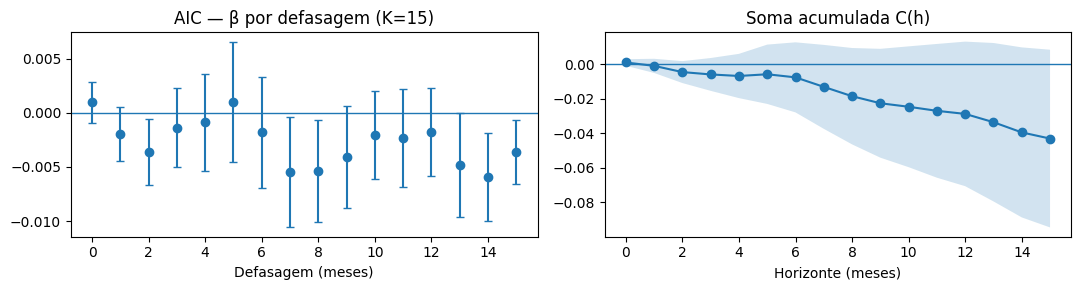

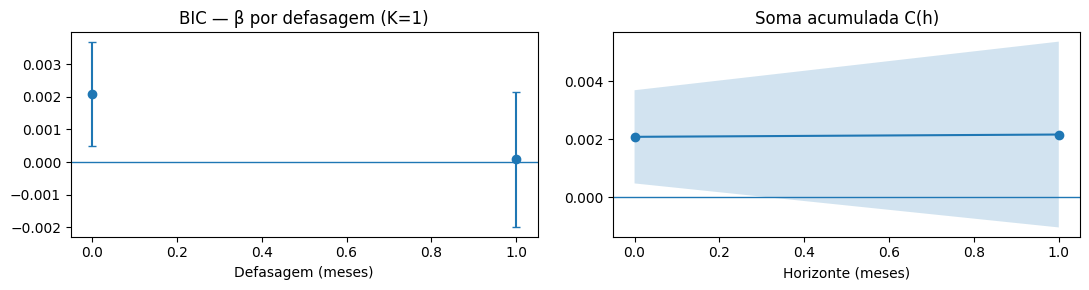

In [5]:
from consolidar_analises_finais import dlm as construir_perfis
if not (A/'dlm_betas_por_lag.csv').exists(): construir_perfis()
P=pd.read_csv(A/'dlm_betas_por_lag.csv')
C=pd.read_csv(A/'dlm_resposta_acumulada.csv')
for per,tipo,crit in [('Pré','tipo_chuvas_intensas','AIC'),('Pré','tipo_chuvas_intensas','BIC')]:
    q=P[(P.periodo==per)&(P.tipologia==tipo)&(P.criterio==crit)&(P.covariancia=='dk_regra')].sort_values('k')
    v=C[(C.periodo==per)&(C.tipologia==tipo)&(C.criterio==crit)&(C.covariancia=='dk_regra')].sort_values('h')
    fig,ax=plt.subplots(1,2,figsize=(11,3))
    ax[0].errorbar(q.k,q.coef_beta_k,yerr=[q.coef_beta_k-q.ic95_inf,q.ic95_sup-q.coef_beta_k],fmt='o',capsize=3)
    ax[0].axhline(0,linewidth=1);ax[0].set_title(f'{crit} — β por defasagem (K={len(q)-1})');ax[0].set_xlabel('Defasagem (meses)')
    ax[1].plot(v.h,v.acum_0h,marker='o');ax[1].fill_between(v.h,v.ic95_inf,v.ic95_sup,alpha=.2)
    ax[1].axhline(0,linewidth=1);ax[1].set_title('Soma acumulada C(h)');ax[1].set_xlabel('Horizonte (meses)')
    plt.tight_layout();plt.show()

## 6. Resultados

AIC e BIC selecionam K distintos em oito cenários estimáveis. O BIC escolhe K=1 em todos os 29. Não há rejeições protegidas com BIC + DK regra. Os K longos de Chuvas Intensas e Vendavais/Ciclones foram auditados numericamente; a interpretação final depende da estabilidade estatística entre inferências e do suporte dos registros.